# Linear Regression: Guided Workshop
Fatal Error AI Club

Can we predict student performance from hours studied? The provided file is `Student_Performance.csv`. Its target is `Performance Index`, so we predict that value rather than an exam score.

Open this notebook from the `notebooks` folder and run the cells in order.

## 1. Import the libraries
Pandas reads the data, matplotlib draws the plot, and scikit-learn trains and evaluates the model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

## 2. Load the data
The CSV is in the neighboring `datasets` folder.

In [2]:
df = pd.read_csv("../datasets/Student_Performance.csv")

## 3. Look at the first five rows

In [3]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


## 4. Plot hours studied and performance

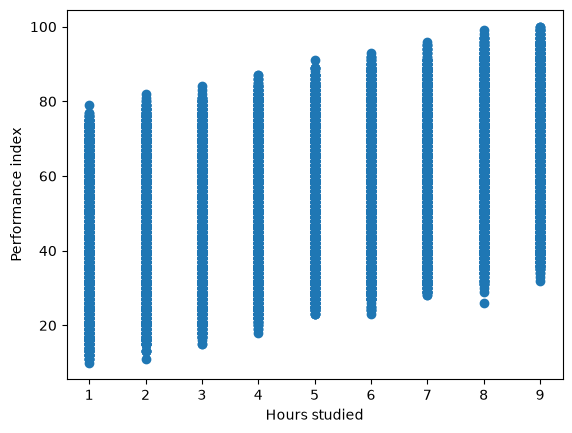

In [4]:
plt.scatter(df["Hours Studied"], df["Performance Index"])
plt.xlabel("Hours studied")
plt.ylabel("Performance index")
plt.show()

## 5. Choose the input and target
`X` holds the input: hours studied. Double brackets keep it as a table with one column.

`y` holds the target: the performance index we want to predict.

In [5]:
X = df[["Hours Studied"]]
y = df["Performance Index"]

## 6. Split the data
Use 80% for training and 20% for testing. `random_state=42` makes the split repeatable.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 7. Create the model

In [7]:
model = LinearRegression()

## 8. Train the model
`.fit()` learns the relationship between the training inputs and targets.

In [8]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.78]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Hours Studied']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,41.44
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


## 9. Predict the test values
`.predict()` uses the trained model to estimate a target for each input.

In [9]:
predictions = model.predict(X_test)

## 10. Measure the error
Mean absolute error (MAE) is the average absolute difference between the actual and predicted values. Lower is better; the units are performance-index points.

In [10]:
mae = mean_absolute_error(y_test, predictions)
print(mae)

15.53389374342778


## 11. Try a new input
Predict the performance index for a student who studies for 6 hours. Use the same column name as the training data.

In [11]:
predictions = model.predict(pd.DataFrame({"Hours Studied": [6]}))
print(predictions[0])

58.14243747356039
